# SHAP

Which inputs moved the first held-out strength prediction away from a training reference? Exact SHAP expresses the difference as additive contributions in MPa.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Predictive model

The forest is trained on concrete recipes that do not appear in the test partition.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from gallery.tabular import concrete_split

import pandas as pd
import shap

## Held-out performance

The explanation refers to this fitted model and its output scale.

In [3]:
X, X_test, y, y_test, groups = concrete_split()
forest = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=3, max_features=0.85, random_state=17, n_jobs=1
)
forest.fit(X, y)
prediction = forest.predict(X_test)
print(
    f"Held-out MAE {mean_absolute_error(y_test,prediction):.2f} MPa | RMSE {root_mean_squared_error(y_test,prediction):.2f} MPa | R² {r2_score(y_test,prediction):.3f}"
)

Held-out MAE 5.45 MPa | RMSE 7.88 MPa | R² 0.791


## Local and global attributions

Thirty-two training mixes define the interventional background. With eight features, all 256 subsets can be evaluated. The global plot summarises the first forty held-out observations.

Maximum absolute additivity error: 0.000000 MPa
First recipe: reference 32.25, predicted 42.02, measured 44.30 MPa


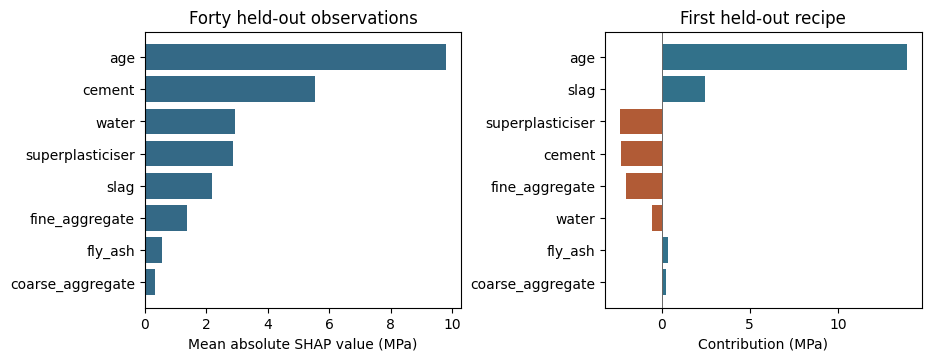

In [4]:
background = X.sample(n=32, random_state=17)
explained = X_test.iloc[:40]


def predict_rows(array):
    return forest.predict(pd.DataFrame(array, columns=X.columns))


masker = shap.maskers.Independent(background, max_samples=len(background))
explainer = shap.Explainer(predict_rows, masker, algorithm="exact", feature_names=list(X.columns))
values = explainer(explained, max_evals=2 ** X.shape[1], silent=True)
base = np.asarray(values.base_values).reshape(-1)
residual = base + values.values.sum(axis=1) - forest.predict(explained)
assert np.max(abs(residual)) < 1e-6
print(f"Maximum absolute additivity error: {np.max(abs(residual)):.6f} MPa")
print(
    f"First recipe: reference {base[0]:.2f}, predicted {prediction[0]:.2f}, measured {y_test.iloc[0]:.2f} MPa"
)
names = np.array(X.columns)
mean_abs = np.abs(values.values).mean(axis=0)
fig, (a, b) = plt.subplots(1, 2, figsize=(9.2, 3.5), constrained_layout=True)
order = np.argsort(mean_abs)
a.barh(names[order], mean_abs[order], color="#346986")
a.set(xlabel="Mean absolute SHAP value (MPa)", title="Forty held-out observations")
local = values.values[0]
order = np.argsort(abs(local))
b.barh(names[order], local[order], color=np.where(local[order] >= 0, "#32718a", "#b15b36"))
b.axvline(0, color="0.4", lw=0.7)
b.set(xlabel="Contribution (MPa)", title="First held-out recipe")
plt.show()

## Reading the result

The contributions add back to the prediction. Changing the background can redistribute credit among correlated ingredients. A contribution describes the fitted forest and its reference distribution.

## References

[Lundberg and Lee, A Unified Approach to Interpreting Model Predictions (2017)](https://arxiv.org/abs/1705.07874)

[SHAP, ExactExplainer](https://shap.readthedocs.io/en/latest/generated/shap.ExactExplainer.html)

[I-Cheng Yeh, Concrete Compressive Strength (UCI), CC BY 4.0](https://doi.org/10.24432/C5PK67)